In [15]:
#1.IMPORT LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

sns.set_theme(style="whitegrid")

print("Banking Fraud Detection - Data Understanding")

Banking Fraud Detection - Data Understanding


In [16]:
# 2. LOAD DATASET

import pandas as pd
from pathlib import Path

# Xác định thư mục dự án
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Đường dẫn đến dữ liệu gốc
DATA_DIR = PROJECT_ROOT / "data" / "raw"

# Lấy danh sách file CSV
files = sorted(DATA_DIR.glob("*.csv"))

# Tạo dictionary chứa các bảng dữ liệu
datasets = {}

for file in files:

    table_name = file.stem

    datasets[table_name] = pd.read_csv(file)

# Kiểm tra kết quả
print("Total files:", len(files))
print("Total datasets:", len(datasets))

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")

Total files: 17
Total datasets: 17
dim_account: 1631 rows, 8 columns
dim_account_type: 3 rows, 7 columns
dim_branch: 8 rows, 10 columns
dim_channel: 4 rows, 2 columns
dim_customer: 1200 rows, 8 columns
dim_date: 289 rows, 10 columns
dim_device: 1699 rows, 6 columns
dim_model: 1 rows, 6 columns
dim_time: 1440 rows, 4 columns
dim_transaction_type: 2 rows, 6 columns
fact_fraud_label_event: 32762 rows, 8 columns
fact_fraud_review: 680 rows, 10 columns
fact_loan_payment: 952 rows, 13 columns
fact_login_event: 36656 rows, 7 columns
fact_risk_assessment: 30000 rows, 11 columns
fact_transaction: 30000 rows, 16 columns
fact_transaction_posting: 59290 rows, 8 columns


In [17]:
#3.DATASET OVERVIEW
overview = []

for name, df in datasets.items():

    overview.append({
        "Table": name,
        "Rows": df.shape[0],
        "Columns": df.shape[1],
        "Missing Values": int(df.isnull().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

overview_df = pd.DataFrame(overview)

display(overview_df)

,Table,Rows,Columns,Missing Values,Duplicate Rows
0,dim_account,1631,8,0,0
1,dim_account_type,3,7,0,0
2,dim_branch,8,10,0,0
3,dim_channel,4,2,0,0
4,dim_customer,1200,8,0,0
5,dim_date,289,10,0,0
6,dim_device,1699,6,0,0
7,dim_model,1,6,0,0
8,dim_time,1440,4,0,0
9,dim_transaction_type,2,6,0,0


### Dataset Overview – Findings

Bộ dữ liệu Banking Fraud Detection System bao gồm 17 bảng, trong đó có 10 bảng Dimension và 7 bảng Fact.

Bảng `fact_transaction` chứa 30.000 bản ghi với 16 thuộc tính, đóng vai trò nguồn dữ liệu giao dịch chính của dự án.

Bảng `fact_fraud_label_event` chứa 32.762 bản ghi với 8 thuộc tính, lưu các sự kiện gắn nhãn liên quan đến giao dịch.

Ngoài ra, bảng `fact_login_event` có 36.656 bản ghi và bảng `fact_risk_assessment` có 30.000 bản ghi. Đây là những nguồn dữ liệu có thể hỗ trợ phân tích hành vi và đánh giá rủi ro giao dịch.

Kết quả khám phá ban đầu cho thấy dữ liệu được tổ chức thành nhiều bảng có vai trò nghiệp vụ khác nhau. Cần tiếp tục kiểm tra khóa và mối quan hệ giữa các bảng trước khi xây dựng tập dữ liệu huấn luyện.

In [18]:
#4.1. Missing Values & Duplicate Rows
quality_report = []

for name, df in datasets.items():

    missing_count = df.isnull().sum().sum()

    duplicate_count = df.duplicated().sum()

    missing_percent = (
        missing_count / df.size * 100
        if df.size > 0 else 0
    )

    quality_report.append({
        "Table": name,
        "Rows": len(df),
        "Columns": df.shape[1],
        "Missing Values": int(missing_count),
        "Missing (%)": round(missing_percent, 2),
        "Duplicate Rows": int(duplicate_count)
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Table,Rows,Columns,Missing Values,Missing (%),Duplicate Rows
0,dim_account,1631,8,0,0.00,0
1,dim_account_type,3,7,0,0.00,0
2,dim_branch,8,10,0,0.00,0
3,dim_channel,4,2,0,0.00,0
4,dim_customer,1200,8,0,0.00,0
5,dim_date,289,10,0,0.00,0
6,dim_device,1699,6,0,0.00,0
7,dim_model,1,6,0,0.00,0
8,dim_time,1440,4,0,0.00,0
9,dim_transaction_type,2,6,0,0.00,0


### Data Quality Assessment – Findings

Kết quả kiểm tra chất lượng dữ liệu trên 17 bảng cho thấy:

- 16 bảng không có giá trị thiếu.
- Bảng `fact_fraud_review` có 432 ô dữ liệu bị thiếu.
- Không phát hiện dòng trùng lặp hoàn toàn trong cả 17 bảng.

Bảng `fact_transaction` và `fact_fraud_label_event` không có giá trị thiếu hoặc dòng trùng lặp hoàn toàn.

Nhìn chung, bộ dữ liệu có mức độ đầy đủ tương đối tốt theo các tiêu chí đã kiểm tra.

Tuy nhiên, việc không có dòng trùng lặp hoàn toàn chưa chứng minh các khóa định danh đều duy nhất. Do đó, cần tiếp tục phân tích khóa và quan hệ giữa các bảng.

In [19]:
#5. FRAUD REVIEW – MISSING VALUES ANALYSIS
#5.1. Kiểm tra dữ liệu thiếu
df_review = datasets["fact_fraud_review"].copy()

review_columns = [
    "reviewed_date_key",
    "reviewed_time_key",
    "reviewed_at",
    "reviewer_user_id"
]

missing_report = pd.DataFrame({
    "Missing Count": df_review.isnull().sum(),
    "Missing (%)": (
        df_review.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing Count,Missing (%)
review_case_id,0,0.00
transaction_id,0,0.00
created_date_key,0,0.00
created_time_key,0,0.00
reviewed_date_key,108,15.88
reviewed_time_key,108,15.88
status,0,0.00
reviewer_user_id,108,15.88
created_at,0,0.00
reviewed_at,108,15.88


In [20]:
#5.2. Kiểm tra các dòng bị thiếu
missing_mask = df_review[review_columns].isna()

print(
    "Rows with all 4 values missing:",
    missing_mask.all(axis=1).sum()
)

print(
    "Rows with at least 1 value missing:",
    missing_mask.any(axis=1).sum()
)

print(
    "Rows with partially missing values:",
    (
        missing_mask.any(axis=1)
        & ~missing_mask.all(axis=1)
    ).sum()
)

Rows with all 4 values missing: 108
Rows with at least 1 value missing: 108
Rows with partially missing values: 0


In [21]:
#5.3. Kiểm tra dữ liệu thiếu theo trạng thái
print("REVIEW STATUS DISTRIBUTION")

print(
    df_review["status"].value_counts(dropna=False)
)

print("\nMISSING VALUES BY STATUS")

display(
    df_review.groupby("status", dropna=False)[
        review_columns
    ].agg(lambda x: x.isna().sum())
)

REVIEW STATUS DISTRIBUTION
status
APPROVED    396
REJECTED    176
OPEN        108
Name: count, dtype: int64

MISSING VALUES BY STATUS


,reviewed_date_key,reviewed_time_key,reviewed_at,reviewer_user_id
status,,,,
APPROVED,0,0,0,0
OPEN,108,108,108,108
REJECTED,0,0,0,0


### Fraud Review – Missing Values Findings

Bảng `fact_fraud_review` gồm 680 hồ sơ rà soát giao dịch.

Kết quả phân tích cho thấy có 432 giá trị thiếu, tập trung ở bốn thuộc tính:

- `reviewed_date_key`
- `reviewed_time_key`
- `reviewed_at`
- `reviewer_user_id`

Mỗi thuộc tính có 108 giá trị thiếu, chiếm 15,88% số hồ sơ.

Phân tích chi tiết xác nhận 108 hồ sơ thiếu đồng thời cả bốn thuộc tính và không có hồ sơ nào chỉ thiếu một phần trong bốn thuộc tính này.

Phân phối trạng thái hồ sơ:

- `APPROVED`: 396 hồ sơ (58,24%).
- `REJECTED`: 176 hồ sơ (25,88%).
- `OPEN`: 108 hồ sơ (15,88%).

Toàn bộ 108 hồ sơ có trạng thái `OPEN` đều thiếu bốn thông tin rà soát, trong khi các hồ sơ `APPROVED` và `REJECTED` không thiếu các thông tin này.

**Kết luận:** Dữ liệu thiếu có mối liên hệ hoàn toàn với trạng thái `OPEN`, phù hợp với giả thuyết rằng các hồ sơ này chưa hoàn thành quá trình rà soát.

**Đề xuất:** Không tự động xóa hoặc điền các giá trị thiếu. Cần xác nhận ý nghĩa nghiệp vụ trước khi quyết định phương án xử lý trong giai đoạn Data Preprocessing.

In [22]:
#6.TRANSACTION KEY ANALYSIS
df_transaction = datasets["fact_transaction"].copy()

print("=== TRANSACTION TABLE ===")

print("Total rows:", len(df_transaction))

print(
    "Unique transaction IDs:",
    df_transaction["transaction_id"].nunique()
)

print(
    "Duplicate transaction IDs:",
    df_transaction["transaction_id"].duplicated().sum()
)

print(
    "Missing transaction IDs:",
    df_transaction["transaction_id"].isna().sum()
)

=== TRANSACTION TABLE ===
Total rows: 30000
Unique transaction IDs: 30000
Duplicate transaction IDs: 0
Missing transaction IDs: 0


### Transaction Key Analysis – Findings

Bảng `fact_transaction` chứa 30.000 bản ghi giao dịch.

Kết quả kiểm tra cho thấy:

- Tổng số giao dịch: 30.000.
- Số giá trị `transaction_id` duy nhất: 30.000.
- Số giá trị `transaction_id` trùng lặp: 0.
- Số giá trị `transaction_id` bị thiếu: 0.

Như vậy, `transaction_id` đáp ứng điều kiện duy nhất và không thiếu trong bảng giao dịch.

Có thể sử dụng thuộc tính này làm khóa định danh giao dịch khi phân tích và liên kết với các bảng dữ liệu liên quan.

In [23]:
#7.FRAUD LABEL KEY ANALYSIS
#7.1. Kiểm tra khóa bảng nhãn
df_fraud = datasets["fact_fraud_label_event"].copy()

print("=== FRAUD LABEL TABLE ===")

print("Total label events:", len(df_fraud))

print(
    "Unique fraud label event IDs:",
    df_fraud["fraud_label_event_id"].nunique()
)

print(
    "Unique transaction IDs:",
    df_fraud["transaction_id"].nunique()
)

print(
    "Repeated transaction IDs:",
    df_fraud["transaction_id"].duplicated().sum()
)

=== FRAUD LABEL TABLE ===
Total label events: 32762
Unique fraud label event IDs: 32762
Unique transaction IDs: 30000
Repeated transaction IDs: 2762


In [24]:
#7.2. Kiểm tra số lần gắn nhãn
label_counts = (
    df_fraud.groupby("transaction_id")
    .size()
)

print("LABEL EVENTS PER TRANSACTION")

print(
    label_counts.value_counts().sort_index()
)

LABEL EVENTS PER TRANSACTION
1    27238
2     2762
Name: count, dtype: int64


### Fraud Label Key Analysis – Findings

Bảng `fact_fraud_label_event` chứa 32.762 sự kiện gắn nhãn.

Kết quả kiểm tra cho thấy:

- Có 32.762 giá trị `fraud_label_event_id` duy nhất.
- Có 30.000 giá trị `transaction_id` khác nhau.
- Có 2.762 lần lặp `transaction_id`.

Phân tích số sự kiện nhãn trên mỗi giao dịch:

- 27.238 giao dịch có một sự kiện gắn nhãn, chiếm 90,79%.
- 2.762 giao dịch có hai sự kiện gắn nhãn, chiếm 9,21%.

Kết quả xác nhận bảng sự kiện nhãn có cấu trúc một-nhiều theo `transaction_id`.

Điều này không nhất thiết là lỗi dữ liệu, vì một giao dịch có thể trải qua nhiều lần đánh giá hoặc cập nhật nhãn.

**Kết luận:** Không nên nối trực tiếp bảng `fact_transaction` với toàn bộ bảng `fact_fraud_label_event` để huấn luyện mô hình, vì các giao dịch có hai sự kiện nhãn sẽ bị nhân đôi.

Cần tiếp tục phân tích giá trị `label`, nguồn gắn nhãn và thời điểm gắn nhãn để xác định quy tắc xây dựng biến mục tiêu.

In [28]:
label_distribution = pd.DataFrame({
    "Count": df_fraud["label"].value_counts(),
    "Percentage (%)": (
        df_fraud["label"]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
    )
})

display(label_distribution)


,Count,Percentage (%)
label,,
LEGITIMATE,27124,82.79
FRAUD,2876,8.78
UNKNOWN,2762,8.43


### Fraud Label Distribution – Findings

Bảng `fact_fraud_label_event` chứa 32.762 sự kiện gắn nhãn với ba loại nhãn:

- `LEGITIMATE`: 27.124 sự kiện (82,79%).
- `FRAUD`: 2.876 sự kiện (8,78%).
- `UNKNOWN`: 2.762 sự kiện (8,43%).

Kết quả cho thấy nhãn `LEGITIMATE` chiếm phần lớn số sự kiện, trong khi nhãn `FRAUD` có tỷ lệ thấp hơn đáng kể.

Điều này cho thấy sự phân bố không đồng đều giữa các nhóm nhãn ở cấp độ sự kiện.

Đáng chú ý, số sự kiện mang nhãn `UNKNOWN` bằng đúng số giao dịch có hai sự kiện gắn nhãn (2.762 giao dịch).

Đây là dấu hiệu cần tiếp tục kiểm tra để xác định liệu các giao dịch có được gắn nhãn `UNKNOWN` trước khi nhận nhãn chính thức hay không.

**Lưu ý:** Phân phối trên được tính theo sự kiện gắn nhãn, chưa phản ánh chính xác tỷ lệ giao dịch gian lận cuối cùng. Cần phân tích nguồn nhãn, sự thay đổi nhãn và thứ tự thời gian trước khi xác định biến mục tiêu cho mô hình Machine Learning.    

In [29]:
# 8.2. LABEL SOURCE ANALYSIS

print("=== LABEL SOURCE DISTRIBUTION ===")

print(
    df_fraud["label_source"].value_counts(dropna=False)
)

print("\n=== LABEL BY SOURCE ===")

label_source_table = pd.crosstab(
    df_fraud["label_source"],
    df_fraud["label"],
    dropna=False
)

display(label_source_table)

=== LABEL SOURCE DISTRIBUTION ===
label_source
SIMULATED_GROUND_TRUTH    30000
SIMULATED_REVIEW           2762
Name: count, dtype: int64

=== LABEL BY SOURCE ===


label,FRAUD,LEGITIMATE,UNKNOWN
label_source,,,
SIMULATED_GROUND_TRUTH,2876,27124,0
SIMULATED_REVIEW,0,0,2762


### 8.2. Label Source Analysis – Findings

Bảng `fact_fraud_label_event` chứa 32.762 sự kiện gắn nhãn, được tạo từ hai nguồn:

- `SIMULATED_GROUND_TRUTH`: 30.000 sự kiện (91,57%).
- `SIMULATED_REVIEW`: 2.762 sự kiện (8,43%).

Phân tích mối quan hệ giữa nguồn và giá trị nhãn cho thấy:

**SIMULATED_GROUND_TRUTH**

- `LEGITIMATE`: 27.124 sự kiện (90,41%).
- `FRAUD`: 2.876 sự kiện (9,59%).
- `UNKNOWN`: 0 sự kiện.

**SIMULATED_REVIEW**

- `UNKNOWN`: 2.762 sự kiện (100%).
- Không có sự kiện mang nhãn `FRAUD` hoặc `LEGITIMATE`.

Kết quả cho thấy hai nguồn gắn nhãn có sự phân tách rõ ràng.

Nguồn `SIMULATED_GROUND_TRUTH` chứa các nhãn xác định, trong khi nguồn `SIMULATED_REVIEW` chỉ chứa nhãn `UNKNOWN`.

Đáng chú ý, số sự kiện thuộc nguồn `SIMULATED_REVIEW` bằng đúng số giao dịch có hai sự kiện gắn nhãn (2.762).

**Kết luận:** `SIMULATED_GROUND_TRUTH` là nguồn ứng viên để xây dựng biến mục tiêu cho mô hình Machine Learning.

Tuy nhiên, cần kiểm tra tính duy nhất của nhãn theo từng giao dịch và quan hệ giữa hai nguồn trước khi lựa chọn nhãn mục tiêu.

Không nên sử dụng trực tiếp toàn bộ 32.762 sự kiện để tính tỷ lệ giao dịch gian lận vì có thể đếm lặp giao dịch.

In [33]:
# 8.3.1. LABEL CHANGE ANALYSIS

label_changes = (
    df_fraud.groupby("transaction_id")["label"]
    .nunique(dropna=False)
)

print("=== LABEL CHANGE ANALYSIS ===")

print(
    "Transactions with multiple distinct labels:",
    (label_changes > 1).sum()
)

print(
    "Transactions with one distinct label:",
    (label_changes == 1).sum()
)

=== LABEL CHANGE ANALYSIS ===
Transactions with multiple distinct labels: 2762
Transactions with one distinct label: 27238


In [ ]:
# 8.3.2. LABEL SOURCE COMBINATION

source_counts = pd.crosstab(
    df_fraud["transaction_id"],
    df_fraud["label_source"]
)

print("=== LABEL SOURCE COMBINATIONS ===")

display(
    source_counts.value_counts().rename("Transactions")
)

print("\n=== SOURCE UNIQUENESS CHECK ===")

ground_truth = df_fraud[
    df_fraud["label_source"] == "SIMULATED_GROUND_TRUTH"
]

print(
    "Ground truth events:",
    len(ground_truth)
)

print(
    "Unique ground truth transactions:",
    ground_truth["transaction_id"].nunique()
)

print(
    "Duplicate ground truth transaction IDs:",
    ground_truth["transaction_id"].duplicated().sum()
)

print(
    "Transactions without ground truth:",
    len(
        set(df_transaction["transaction_id"])
        - set(ground_truth["transaction_id"])
    )
)

=== LABEL SOURCE COMBINATIONS ===


SIMULATED_GROUND_TRUTH  SIMULATED_REVIEW
1                       0                   27238
                        1                    2762
Name: Transactions, dtype: int64


=== SOURCE UNIQUENESS CHECK ===
Ground truth events: 30000
Unique ground truth transactions: 30000
Duplicate ground truth transaction IDs: 0
Transactions without ground truth: 0


### 8.3.1. Label Source Combination – Findings

Phân tích cấu trúc nguồn nhãn theo từng giao dịch cho thấy:

- 27.238 giao dịch (90,79%) có một sự kiện `SIMULATED_GROUND_TRUTH` và không có sự kiện `SIMULATED_REVIEW`.
- 2.762 giao dịch (9,21%) có một sự kiện `SIMULATED_GROUND_TRUTH` và một sự kiện `SIMULATED_REVIEW`.

Kết quả kiểm tra tính duy nhất của nguồn Ground Truth xác nhận:

- Tổng số sự kiện Ground Truth: 30.000.
- Số giao dịch có Ground Truth: 30.000.
- Số giao dịch có nhiều hơn một sự kiện Ground Truth: 0.
- Số giao dịch không có Ground Truth: 0.

Như vậy, toàn bộ 30.000 giao dịch đều có đúng một sự kiện Ground Truth.

Phân phối nhãn Ground Truth gồm:

- `LEGITIMATE`: 27.124 giao dịch (90,41%).
- `FRAUD`: 2.876 giao dịch (9,59%).

Dữ liệu có hiện tượng mất cân bằng lớp, trong đó giao dịch hợp lệ chiếm phần lớn.

**Kết luận:** Nguồn `SIMULATED_GROUND_TRUTH` phù hợp để xem xét xây dựng biến mục tiêu cho bài toán phát hiện gian lận có giám sát.

Các sự kiện `SIMULATED_REVIEW` mang nhãn `UNKNOWN` không nên được coi là nhãn gian lận đã xác nhận.

Cần tiếp tục kiểm tra thời điểm gắn nhãn và quan hệ thời gian với giao dịch trước khi hoàn thiện phương án xây dựng tập dữ liệu huấn luyện.

In [34]:
# 8.4.1. TIMESTAMP VALIDATION

df_fraud_time = df_fraud.copy()
df_transaction_time = df_transaction.copy()

# Chuyển dữ liệu thời gian sang datetime
df_fraud_time["labeled_at"] = pd.to_datetime(
    df_fraud_time["labeled_at"],
    errors="coerce"
)

df_transaction_time["transaction_at"] = pd.to_datetime(
    df_transaction_time["transaction_at"],
    errors="coerce"
)

print("=== TIMESTAMP VALIDATION ===")

print(
    "Invalid labeled_at:",
    df_fraud_time["labeled_at"].isna().sum()
)

print(
    "Invalid transaction_at:",
    df_transaction_time["transaction_at"].isna().sum()
)

=== TIMESTAMP VALIDATION ===
Invalid labeled_at: 0
Invalid transaction_at: 0


In [35]:
# 8.4.2. LABEL TIMING VS TRANSACTION

label_timing = df_fraud_time.merge(
    df_transaction_time[
        ["transaction_id", "transaction_at"]
    ],
    on="transaction_id",
    how="left",
    validate="many_to_one"
)

# Chỉ sử dụng các bản ghi có thời gian hợp lệ
valid_timing = label_timing.dropna(
    subset=["labeled_at", "transaction_at"]
).copy()

# Tính khoảng cách thời gian theo giờ
valid_timing["delay_hours"] = (
    valid_timing["labeled_at"]
    - valid_timing["transaction_at"]
).dt.total_seconds() / 3600

print("=== LABEL TIMING VS TRANSACTION ===")

print(
    "Events before transaction:",
    (valid_timing["delay_hours"] < 0).sum()
)

print(
    "Events at transaction time:",
    (valid_timing["delay_hours"] == 0).sum()
)

print(
    "Events after transaction:",
    (valid_timing["delay_hours"] > 0).sum()
)

print("\n=== DELAY BY LABEL SOURCE ===")

display(
    valid_timing.groupby("label_source")[
        "delay_hours"
    ].describe().round(2)
)

=== LABEL TIMING VS TRANSACTION ===
Events before transaction: 0
Events at transaction time: 0
Events after transaction: 32762

=== DELAY BY LABEL SOURCE ===


,count,mean,std,min,25%,50%,75%,max
label_source,,,,,,,,
SIMULATED_GROUND_TRUTH,30000.0,192.95,89.72,48.0,120.0,192.0,264.0,336.0
SIMULATED_REVIEW,2762.0,8.01,4.29,1.0,4.0,8.0,12.0,15.0


In [36]:
# 8.4.3. GROUND TRUTH VS REVIEW TIMING

# Lấy thời gian Ground Truth
gt_time = df_fraud_time[
    df_fraud_time["label_source"] == "SIMULATED_GROUND_TRUTH"
][["transaction_id", "labeled_at"]].rename(
    columns={"labeled_at": "ground_truth_at"}
)

# Lấy thời gian Review
review_time = df_fraud_time[
    df_fraud_time["label_source"] == "SIMULATED_REVIEW"
][["transaction_id", "labeled_at"]].rename(
    columns={"labeled_at": "review_at"}
)

# Ghép hai nguồn theo giao dịch
review_comparison = review_time.merge(
    gt_time,
    on="transaction_id",
    how="inner",
    validate="one_to_one"
)

# Tính chênh lệch thời gian
review_comparison["review_minus_gt_hours"] = (
    review_comparison["review_at"]
    - review_comparison["ground_truth_at"]
).dt.total_seconds() / 3600

valid_comparison = review_comparison.dropna(
    subset=["review_minus_gt_hours"]
)

print("=== GROUND TRUTH VS REVIEW TIMING ===")

print(
    "Transactions compared:",
    len(review_comparison)
)

print(
    "Review before Ground Truth:",
    (valid_comparison["review_minus_gt_hours"] < 0).sum()
)

print(
    "Review at same time:",
    (valid_comparison["review_minus_gt_hours"] == 0).sum()
)

print(
    "Review after Ground Truth:",
    (valid_comparison["review_minus_gt_hours"] > 0).sum()
)

print("\n=== TIME DIFFERENCE SUMMARY ===")

display(
    valid_comparison["review_minus_gt_hours"]
    .describe()
    .round(2)
)

=== GROUND TRUTH VS REVIEW TIMING ===
Transactions compared: 2762
Review before Ground Truth: 2762
Review at same time: 0
Review after Ground Truth: 0

=== TIME DIFFERENCE SUMMARY ===


count    2762.00
mean     -182.98
std        90.83
min      -335.00
25%      -261.00
50%      -180.50
75%      -107.00
max       -33.00
Name: review_minus_gt_hours, dtype: float64

In [ ]:
### 8.4.3. Ground Truth vs Review Timing – Findings

Phân tích thời gian của 2.762 giao dịch có cả hai sự kiện `SIMULATED_REVIEW` và `SIMULATED_GROUND_TRUTH` cho thấy:

- 2.762 giao dịch (100%) có sự kiện Review xảy ra trước Ground Truth.
- Không có giao dịch nào có Review cùng thời điểm hoặc sau Ground Truth.

Khoảng cách thời gian giữa hai sự kiện:

- Trung bình: 182,98 giờ (khoảng 7,62 ngày).
- Trung vị: 180,50 giờ (khoảng 7,52 ngày).
- Ngắn nhất: 33 giờ.
- Dài nhất: 335 giờ (khoảng 13,96 ngày).
- Độ lệch chuẩn: 90,83 giờ.

Kết quả cho thấy các sự kiện `SIMULATED_REVIEW` mang nhãn `UNKNOWN` luôn được ghi nhận trước các sự kiện `SIMULATED_GROUND_TRUTH` tương ứng.

Điều này phù hợp với khả năng dữ liệu mô phỏng quá trình một giao dịch được ghi nhận ở trạng thái chưa xác định trước khi có nhãn cuối cùng.

**Kết luận:** `SIMULATED_GROUND_TRUTH` là nguồn nhãn phù hợp để xem xét xây dựng biến mục tiêu cho mô hình học có giám sát. Tuy nhiên, cần tiếp tục kiểm tra thời điểm Ground Truth so với thời điểm giao dịch và bảo đảm các đặc trưng đầu vào không chứa thông tin chỉ xuất hiện sau thời điểm dự đoán.

### 8.4.4. Label Timestamp Analysis – Findings

#### Timestamp Validation

Kiểm tra tính hợp lệ của dữ liệu thời gian cho thấy:

- Không có giá trị `labeled_at` không hợp lệ.
- Không có giá trị `transaction_at` không hợp lệ.
- Toàn bộ 32.762 sự kiện gắn nhãn đều có thời gian hợp lệ.

#### Label Timing vs Transaction

Kết quả phân tích xác nhận:

- 0 sự kiện gắn nhãn xảy ra trước giao dịch.
- 0 sự kiện gắn nhãn xảy ra cùng thời điểm giao dịch.
- 32.762 sự kiện (100%) được ghi nhận sau thời điểm giao dịch.

#### Ground Truth Delay

Nguồn `SIMULATED_GROUND_TRUTH` gồm 30.000 sự kiện.

- Độ trễ trung bình: 192,95 giờ (khoảng 8,04 ngày).
- Độ trễ trung vị: 192 giờ (8 ngày).
- Độ trễ nhỏ nhất: 48 giờ (2 ngày).
- Độ trễ lớn nhất: 336 giờ (14 ngày).

Như vậy, nhãn Ground Truth được ghi nhận sau giao dịch từ 2 đến 14 ngày.

#### Review Delay

Nguồn `SIMULATED_REVIEW` gồm 2.762 sự kiện.

- Độ trễ trung bình: 8,01 giờ.
- Độ trễ trung vị: 8 giờ.
- Độ trễ nhỏ nhất: 1 giờ.
- Độ trễ lớn nhất: 15 giờ.

Các sự kiện Review được ghi nhận sớm hơn Ground Truth và chỉ mang nhãn `UNKNOWN`.

#### Ground Truth vs Review Timing

Trong 2.762 giao dịch có cả hai nguồn nhãn:

- 100% sự kiện Review xảy ra trước Ground Truth.
- Không có sự kiện Review nào xảy ra cùng thời điểm hoặc sau Ground Truth.
- Khoảng cách trung bình giữa Review và Ground Truth là 182,98 giờ (khoảng 7,62 ngày).
- Khoảng cách ngắn nhất là 33 giờ và dài nhất là 335 giờ.

#### Implications for Machine Learning

Các kết quả trên cho thấy:

1. `SIMULATED_GROUND_TRUTH` là nguồn nhãn phù hợp để xem xét xây dựng biến mục tiêu cho bài toán phân loại gian lận.
2. Nhãn Ground Truth được xác định sau thời điểm giao dịch, vì vậy không thể xem đây là thông tin đã biết tại thời điểm dự đoán.
3. Các sự kiện Review có nhãn `UNKNOWN` không nên được sử dụng trực tiếp làm nhãn mục tiêu.
4. Khi xây dựng tập dữ liệu huấn luyện, cần tránh sử dụng các trường thông tin chỉ xuất hiện sau thời điểm giao dịch làm đặc trưng đầu vào.
5. Cần cân nhắc độ trễ xác nhận nhãn khi thiết kế phương pháp chia dữ liệu theo thời gian và đánh giá mô hình.

**Conclusion:** Dữ liệu thời gian gắn nhãn có cấu trúc nhất quán với một quy trình xác nhận nhãn sau giao dịch. Không phát hiện sự kiện nhãn nào có thời điểm trước hoặc trùng thời điểm giao dịch. Tuy nhiên, cần tiếp tục kiểm soát nguy cơ data leakage trong các bước xây dựng đặc trưng và huấn luyện mô hình.

In [37]:
# 9.1. TRANSACTION STRUCTURE

print("=== TRANSACTION SHAPE ===")
print(df_transaction.shape)

print("\n=== TRANSACTION COLUMNS ===")
print(df_transaction.columns.tolist())

print("\n=== TRANSACTION DATA TYPES ===")
print(df_transaction.dtypes.to_string())

print("\n=== TRANSACTION SAMPLE ===")
display(df_transaction.head())

=== TRANSACTION SHAPE ===
(30000, 16)

=== TRANSACTION COLUMNS ===
['transaction_id', 'transaction_code', 'date_key', 'time_key', 'customer_key', 'source_account_key', 'destination_account_key', 'branch_key', 'transaction_type_key', 'channel_key', 'device_key', 'amount', 'fee', 'currency', 'status', 'transaction_at']

=== TRANSACTION DATA TYPES ===
transaction_id               int64
transaction_code               str
date_key                     int64
time_key                     int64
customer_key                 int64
source_account_key           int64
destination_account_key      int64
branch_key                   int64
transaction_type_key         int64
channel_key                    str
device_key                   int64
amount                     float64
fee                        float64
currency                       str
status                         str
transaction_at                 str

=== TRANSACTION SAMPLE ===


,transaction_id,transaction_code,date_key,time_key,customer_key,source_account_key,destination_account_key,branch_key,transaction_type_key,channel_key,device_key,amount,fee,currency,status,transaction_at
0,1,TXN00000000000001,20260101,0,934,1281,825,5,1,InternetBanking,1331,614000.0,0.0,VND,Success,2026-01-01 00:00:15
1,2,TXN00000000000002,20260101,20,223,304,273,4,1,ATM,-1,20877000.0,0.0,VND,Success,2026-01-01 00:20:14
2,3,TXN00000000000003,20260101,28,1111,1513,64,7,1,InternetBanking,1576,63286000.0,0.0,VND,Success,2026-01-01 00:28:19
3,4,TXN00000000000004,20260101,104,282,390,137,5,1,MobileBanking,402,3586000.0,0.0,VND,Success,2026-01-01 01:04:46
4,5,TXN00000000000005,20260101,113,245,335,904,8,1,MobileBanking,346,1995000.0,0.0,VND,Success,2026-01-01 01:13:14


In [39]:
# 9.2.1. TRANSACTION AMOUNT SUMMARY

print("=== TRANSACTION AMOUNT SUMMARY ===")

display(
    df_transaction["amount"].describe().round(2)
)

print("\n=== AMOUNT DATA QUALITY ===")

print(
    "Missing amounts:",
    df_transaction["amount"].isna().sum()
)

print(
    "Zero amounts:",
    (df_transaction["amount"] == 0).sum()
)

print(
    "Negative amounts:",
    (df_transaction["amount"] < 0).sum()
)

print("\n=== AMOUNT PERCENTILES ===")

display(
    df_transaction["amount"]
    .quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .round(2)
)

=== TRANSACTION AMOUNT SUMMARY ===


count       30000.00
mean     11433967.87
std      18135247.55
min        150000.00
25%       1549000.00
50%       2935000.00
75%       9762000.00
max      84866000.00
Name: amount, dtype: float64


=== AMOUNT DATA QUALITY ===
Missing amounts: 0
Zero amounts: 0
Negative amounts: 0

=== AMOUNT PERCENTILES ===


0.01      205000.0
0.05      423000.0
0.25     1549000.0
0.50     2935000.0
0.75     9762000.0
0.95    56240800.0
0.99    71062020.0
Name: amount, dtype: float64

### 9.2.1. Transaction Amount Summary – Findings

Phân tích 30.000 giao dịch cho thấy:

- Giá trị giao dịch trung bình: 11.433.967,87 VND.
- Giá trị trung vị: 2.935.000 VND.
- Độ lệch chuẩn: 18.135.247,55 VND.
- Giá trị nhỏ nhất: 150.000 VND.
- Giá trị lớn nhất: 84.866.000 VND.

Giá trị trung bình cao hơn trung vị khoảng 3,9 lần, cho thấy phân phối giá trị giao dịch có dấu hiệu lệch phải (*right-skewed*).

Phân tích phân vị cho thấy:

- 50% giao dịch có giá trị không vượt quá 2.935.000 VND.
- 75% giao dịch có giá trị không vượt quá 9.762.000 VND.
- 95% giao dịch có giá trị không vượt quá 56.240.800 VND.
- 99% giao dịch có giá trị không vượt quá 71.062.020 VND.

Kiểm tra chất lượng dữ liệu:

- Missing values: 0.
- Zero values: 0.
- Negative values: 0.

**Kết luận:** Giá trị giao dịch có mức độ phân tán lớn và dấu hiệu lệch phải. Các giao dịch có giá trị cao cần được phân tích thêm, đặc biệt khi kết hợp với nhãn gian lận. Tuy nhiên, giá trị giao dịch lớn không đồng nghĩa với gian lận.

Chưa thực hiện loại bỏ ngoại lệ hoặc biến đổi dữ liệu ở giai đoạn Data Understanding.

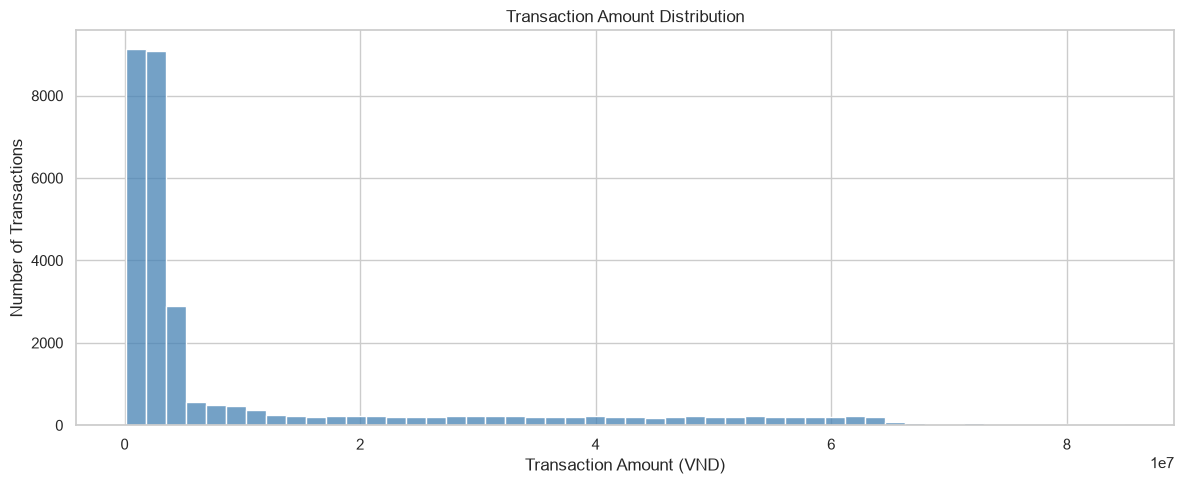

In [40]:
# 9.2.2. TRANSACTION AMOUNT DISTRIBUTION

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))

sns.histplot(
    data=df_transaction,
    x="amount",
    bins=50,
    color="steelblue"
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount (VND)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

In [41]:
# 9.2.3. TRANSACTION AMOUNT OUTLIER ANALYSIS

Q1 = df_transaction["amount"].quantile(0.25)
Q3 = df_transaction["amount"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Xác định giao dịch nằm ngoài ngưỡng IQR
outlier_mask = (
    (df_transaction["amount"] < lower_bound)
    | (df_transaction["amount"] > upper_bound)
)

outlier_count = outlier_mask.sum()

outlier_percentage = (
    outlier_count / len(df_transaction) * 100
)

print("=== TRANSACTION AMOUNT OUTLIER ANALYSIS ===")

print(f"Q1: {Q1:,.2f} VND")
print(f"Q3: {Q3:,.2f} VND")
print(f"IQR: {IQR:,.2f} VND")
print(f"Lower Bound: {lower_bound:,.2f} VND")
print(f"Upper Bound: {upper_bound:,.2f} VND")

print(f"\nTotal Transactions: {len(df_transaction):,}")
print(f"Outlier Transactions: {outlier_count:,}")
print(f"Outlier Percentage: {outlier_percentage:.2f}%")

print("\n=== OUTLIER AMOUNT SUMMARY ===")

display(
    df_transaction.loc[outlier_mask, "amount"]
    .describe()
    .round(2)
)

=== TRANSACTION AMOUNT OUTLIER ANALYSIS ===
Q1: 1,549,000.00 VND
Q3: 9,762,000.00 VND
IQR: 8,213,000.00 VND
Lower Bound: -10,770,500.00 VND
Upper Bound: 22,081,500.00 VND

Total Transactions: 30,000
Outlier Transactions: 5,669
Outlier Percentage: 18.90%

=== OUTLIER AMOUNT SUMMARY ===


count        5669.00
mean     45840425.82
std      14662130.59
min      22098000.00
25%      33376000.00
50%      45194000.00
75%      56937000.00
max      84866000.00
Name: amount, dtype: float64

### 9.2.3. Transaction Amount Outlier Analysis – Findings

Phân tích ngoại lệ giá trị giao dịch bằng phương pháp Interquartile Range (IQR) cho thấy:

- Q1: 1.549.000 VND.
- Q3: 9.762.000 VND.
- IQR: 8.213.000 VND.
- Lower Bound: -10.770.500 VND.
- Upper Bound: 22.081.500 VND.

Trong tổng số 30.000 giao dịch:

- Có 5.669 giao dịch (18,90%) được xác định là ngoại lệ theo IQR.
- Có 24.331 giao dịch (81,10%) nằm trong khoảng giới hạn IQR.
- Toàn bộ ngoại lệ đều thuộc nhóm giao dịch có giá trị cao.

Đặc điểm nhóm ngoại lệ:

- Giá trị trung bình: 45.840.425,82 VND.
- Giá trị trung vị: 45.194.000 VND.
- Giá trị nhỏ nhất: 22.098.000 VND.
- Giá trị lớn nhất: 84.866.000 VND.

**Nhận xét:** Phân phối giá trị giao dịch có dấu hiệu lệch phải, khiến phương pháp IQR đánh dấu một tỷ lệ tương đối lớn các giao dịch có giá trị cao.

**Kết luận:** Không nên tự động loại bỏ các giao dịch ngoại lệ vì chúng có thể chứa thông tin quan trọng đối với bài toán phát hiện gian lận. Cần tiếp tục phân tích mối quan hệ giữa giá trị giao dịch, nhóm ngoại lệ và nhãn gian lận trước khi quyết định phương pháp xử lý dữ liệu.

Ở giai đoạn Data Understanding, các giao dịch ngoại lệ chỉ được xác định và thống kê, chưa bị xóa hoặc điều chỉnh.

In [42]:
# 9.3.1. TRANSACTION CHANNEL DISTRIBUTION

channel_summary = (
    df_transaction["channel_key"]
    .value_counts(dropna=False)
    .rename_axis("channel")
    .reset_index(name="transaction_count")
)

channel_summary["percentage"] = (
    channel_summary["transaction_count"]
    / len(df_transaction)
    * 100
).round(2)

print("=== TRANSACTION CHANNEL DISTRIBUTION ===")

display(channel_summary)

print("\n=== TOTAL TRANSACTIONS ===")
print(channel_summary["transaction_count"].sum())

=== TRANSACTION CHANNEL DISTRIBUTION ===


,channel,transaction_count,percentage
0,MobileBanking,20425,68.08
1,InternetBanking,7483,24.94
2,ATM,1191,3.97
3,Counter,901,3.00



=== TOTAL TRANSACTIONS ===
30000


### 9.3.1. Transaction Channel Distribution – Findings

Phân tích 30.000 giao dịch cho thấy có bốn kênh giao dịch:

- `MobileBanking`: 20.425 giao dịch (68,08%).
- `InternetBanking`: 7.483 giao dịch (24,94%).
- `ATM`: 1.191 giao dịch (3,97%).
- `Counter`: 901 giao dịch (3,00%).

**Nhận xét:**

MobileBanking là kênh có số lượng giao dịch lớn nhất, chiếm hơn hai phần ba tổng số giao dịch.

Hai kênh MobileBanking và InternetBanking có tổng cộng 27.908 giao dịch, tương đương khoảng 93,03% dữ liệu.

Trong khi đó, ATM và Counter chỉ chiếm khoảng 6,97%.

**Kết luận:** Phân phối giao dịch theo kênh không đồng đều, trong đó các kênh ngân hàng trực tuyến chiếm ưu thế.

Số lượng giao dịch lớn không đồng nghĩa với tỷ lệ gian lận cao. Cần tiếp tục phân tích mối quan hệ giữa kênh giao dịch và nhãn gian lận để đánh giá rủi ro của từng kênh.

In [43]:
# 9.3.2. TRANSACTION AMOUNT BY CHANNEL

amount_by_channel = (
    df_transaction
    .groupby("channel_key")["amount"]
    .agg(
        transaction_count="count",
        mean_amount="mean",
        median_amount="median",
        min_amount="min",
        max_amount="max",
        std_amount="std"
    )
    .round(2)
    .sort_values("mean_amount", ascending=False)
)

print("=== TRANSACTION AMOUNT BY CHANNEL ===")

display(amount_by_channel)

=== TRANSACTION AMOUNT BY CHANNEL ===


,transaction_count,mean_amount,median_amount,min_amount,max_amount,std_amount
channel_key,,,,,,
Counter,901,12084405.11,2979000.0,155000.0,84516000.0,19098256.52
MobileBanking,20425,11518734.25,2937000.0,150000.0,84770000.0,18171552.38
ATM,1191,11289955.50,2940000.0,158000.0,84163000.0,17822139.30
InternetBanking,7483,11147200.72,2924000.0,150000.0,84866000.0,17965032.87


### 9.3.2. Findings

- **Counter** có giá trị giao dịch trung bình cao nhất: **12,08 triệu VND**.
- **InternetBanking** có giá trị trung bình thấp nhất: **11,15 triệu VND**.
- Trung vị của cả bốn kênh khá tương đồng, khoảng **2,92–2,98 triệu VND**.
- Giá trị trung bình ở tất cả các kênh đều cao hơn nhiều so với trung vị, cho thấy phân phối có dấu hiệu lệch phải.

**Kết luận:** Giá trị giao dịch giữa các kênh không chênh lệch quá lớn. Cần kết hợp với nhãn gian lận để đánh giá rủi ro của từng kênh.

In [44]:
# 9.4.1. TRANSACTION STATUS DISTRIBUTION

status_summary = (
    df_transaction["status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="transaction_count")
)

status_summary["percentage"] = (
    status_summary["transaction_count"]
    / len(df_transaction) * 100
).round(2)

print("=== TRANSACTION STATUS DISTRIBUTION ===")

display(status_summary)

=== TRANSACTION STATUS DISTRIBUTION ===


,status,transaction_count,percentage
0,Success,29645,98.82
1,Rejected,247,0.82
2,Pending,108,0.36


### 9.4.1. Findings

- **Success:** 29.645 giao dịch (98,82%), chiếm đa số.
- **Rejected:** 247 giao dịch (0,82%).
- **Pending:** 108 giao dịch (0,36%).

**Kết luận:** Hầu hết giao dịch đều thành công. Giao dịch bị từ chối và đang chờ xử lý chiếm tỷ lệ rất nhỏ.

**Lưu ý:** Trạng thái giao dịch không trực tiếp xác định giao dịch có gian lận hay không.

In [45]:
# 9.5.1. TRANSACTION TYPE LOOKUP

df_transaction_type = datasets["dim_transaction_type"].copy()

print("=== TRANSACTION TYPE TABLE ===")
print("Shape:", df_transaction_type.shape)

display(df_transaction_type.head(10))

print("\n=== COLUMNS ===")
print(df_transaction_type.columns.tolist())

=== TRANSACTION TYPE TABLE ===
Shape: (2, 6)


,transaction_type_key,transaction_type_id,type_code,type_name,description,status
0,1,1,TRANSFER,Chuyen khoan,Chuyen tien noi bo,Active
1,2,2,LOAN_PAYMENT,Tra no,Thanh toan khoan vay,Active



=== COLUMNS ===
['transaction_type_key', 'transaction_type_id', 'type_code', 'type_name', 'description', 'status']


In [46]:
# 9.5.2. TRANSACTION TYPE DISTRIBUTION

# Nối bảng giao dịch với bảng loại giao dịch
df_transaction_type_merged = df_transaction.merge(
    df_transaction_type[
        ["transaction_type_key", "type_code", "type_name"]
    ],
    on="transaction_type_key",
    how="left",
    validate="many_to_one"
)

# Thống kê số lượng theo loại giao dịch
type_summary = (
    df_transaction_type_merged["type_code"]
    .value_counts(dropna=False)
    .rename_axis("transaction_type")
    .reset_index(name="transaction_count")
)

type_summary["percentage"] = (
    type_summary["transaction_count"]
    / len(df_transaction) * 100
).round(2)

print("=== TRANSACTION TYPE DISTRIBUTION ===")
display(type_summary)

print("\n=== DATA VALIDATION ===")
print("Total transactions:", len(df_transaction_type_merged))
print("Unmatched transaction types:",
      df_transaction_type_merged["type_code"].isna().sum())

=== TRANSACTION TYPE DISTRIBUTION ===


,transaction_type,transaction_count,percentage
0,TRANSFER,29045,96.82
1,LOAN_PAYMENT,955,3.18



=== DATA VALIDATION ===
Total transactions: 30000
Unmatched transaction types: 0


### 9.5.2. Findings

- **TRANSFER:** 29.045 giao dịch (96,82%), chiếm đa số.
- **LOAN_PAYMENT:** 955 giao dịch (3,18%).
- Cả 30.000 giao dịch đều khớp với bảng danh mục loại giao dịch.

**Kết luận:** Dữ liệu chủ yếu gồm các giao dịch chuyển khoản. Không có lỗi liên kết giữa bảng giao dịch và bảng loại giao dịch.

In [47]:
# 9.6. TRANSACTION DISTRIBUTION BY HOUR

# Lấy giờ từ thời điểm giao dịch
transaction_hour = pd.to_datetime(
    df_transaction["transaction_at"]
).dt.hour

# Đếm số giao dịch theo từng giờ
hour_summary = (
    transaction_hour
    .value_counts()
    .sort_index()
    .rename_axis("hour")
    .reset_index(name="transaction_count")
)

hour_summary["percentage"] = (
    hour_summary["transaction_count"]
    / len(df_transaction) * 100
).round(2)

print("=== TRANSACTION DISTRIBUTION BY HOUR ===")
display(hour_summary)

=== TRANSACTION DISTRIBUTION BY HOUR ===


,hour,transaction_count,percentage
0,0,1226,4.09
1,1,1255,4.18
2,2,1283,4.28
3,3,1304,4.35
4,4,1263,4.21
5,5,1252,4.17
6,6,1206,4.02
7,7,1300,4.33
8,8,1307,4.36
9,9,1294,4.31


### 9.6. Findings

- Giao dịch phân bố khá đồng đều trong 24 giờ.
- **8 giờ** có nhiều giao dịch nhất: 1.307 (4,36%).
- **18 giờ** có ít giao dịch nhất: 1.163 (3,88%).
- Không có khung giờ nào tập trung quá nhiều giao dịch.

**Kết luận:** Chưa phát hiện sự bất thường rõ rệt về số lượng giao dịch theo giờ. Cần phân tích thêm tỷ lệ gian lận theo giờ để đánh giá rủi ro.

In [51]:
# 9.7. FRAUD RATE BY HOUR

# Kiểm tra mỗi giao dịch chỉ có một nhãn
assert df_gt["transaction_id"].is_unique

# Chỉ lấy các cột cần thiết
df_hourly_fraud = df_transaction[
    ["transaction_id", "transaction_at"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

# Kiểm tra dữ liệu sau khi nối
assert df_hourly_fraud["label"].notna().all()
assert df_hourly_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

# Lấy giờ giao dịch
df_hourly_fraud["hour"] = pd.to_datetime(
    df_hourly_fraud["transaction_at"]
).dt.hour

# Đánh dấu giao dịch gian lận
df_hourly_fraud["is_fraud"] = (
    df_hourly_fraud["label"] == "FRAUD"
).astype(int)

# Thống kê theo giờ
fraud_by_hour = (
    df_hourly_fraud
    .groupby("hour")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_hour["fraud_rate"] = (
    fraud_by_hour["fraud_count"]
    / fraud_by_hour["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY HOUR ===")

display(fraud_by_hour)

=== FRAUD RATE BY HOUR ===


,total_transactions,fraud_count,fraud_rate
hour,,,
0,1226,115,9.38
1,1255,116,9.24
2,1283,132,10.29
3,1304,137,10.51
4,1263,135,10.69
5,1252,119,9.50
6,1206,123,10.20
7,1300,121,9.31
8,1307,136,10.41


### 9.7. Findings

- Tỷ lệ gian lận trung bình toàn bộ dữ liệu là **9,59%**.
- **9 giờ** có tỷ lệ gian lận cao nhất: **11,21%**.
- **21 giờ** có tỷ lệ gian lận thấp nhất: **7,43%**.
- Tỷ lệ gian lận thay đổi theo giờ, dao động từ **7,43% đến 11,21%**.

**Kết luận:** Giờ giao dịch có thể là một đặc trưng hữu ích cho mô hình Fraud Detection, nhưng cần kiểm chứng thêm khi xây dựng mô hình.

In [52]:
# 9.8. FRAUD RATE BY CHANNEL

# Chỉ lấy dữ liệu cần thiết
df_channel_fraud = df_transaction[
    ["transaction_id", "channel_key"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

# Kiểm tra nhãn hợp lệ
assert df_channel_fraud["label"].notna().all()
assert df_channel_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

# Đánh dấu gian lận
df_channel_fraud["is_fraud"] = (
    df_channel_fraud["label"] == "FRAUD"
).astype(int)

# Tính tỷ lệ gian lận theo kênh
fraud_by_channel = (
    df_channel_fraud
    .groupby("channel_key")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_channel["fraud_rate"] = (
    fraud_by_channel["fraud_count"]
    / fraud_by_channel["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY CHANNEL ===")
display(fraud_by_channel)

=== FRAUD RATE BY CHANNEL ===


,total_transactions,fraud_count,fraud_rate
channel_key,,,
ATM,1191,134,11.25
Counter,901,78,8.66
InternetBanking,7483,700,9.35
MobileBanking,20425,1964,9.62


### 9.8. Findings

- **ATM** có tỷ lệ gian lận cao nhất: **11,25%**.
- **Counter** có tỷ lệ gian lận thấp nhất: **8,66%**.
- **MobileBanking** có nhiều giao dịch gian lận nhất: **1.964 giao dịch**.
- Tỷ lệ gian lận giữa các kênh dao động từ **8,66% đến 11,25%**.

**Kết luận:** Kênh giao dịch có thể liên quan đến rủi ro gian lận, nhưng cần kiểm chứng thêm bằng phân tích thống kê hoặc mô hình.

In [53]:
# 9.9. FRAUD RATE BY TRANSACTION TYPE

df_type_fraud = df_transaction_type_merged[
    ["transaction_id", "type_code"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

# Kiểm tra nhãn
assert df_type_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

df_type_fraud["is_fraud"] = (
    df_type_fraud["label"] == "FRAUD"
).astype(int)

fraud_by_type = (
    df_type_fraud
    .groupby("type_code")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_type["fraud_rate"] = (
    fraud_by_type["fraud_count"]
    / fraud_by_type["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY TRANSACTION TYPE ===")
display(fraud_by_type)

=== FRAUD RATE BY TRANSACTION TYPE ===


,total_transactions,fraud_count,fraud_rate
type_code,,,
LOAN_PAYMENT,955,0,0.0
TRANSFER,29045,2876,9.9


### 9.9. Findings

- **TRANSFER:** 2.876/29.045 giao dịch gian lận (**9,90%**).
- **LOAN_PAYMENT:** 0/955 giao dịch gian lận (**0%**).
- Toàn bộ giao dịch gian lận đều thuộc loại `TRANSFER`.

**Kết luận:** Loại giao dịch có liên hệ với nhãn gian lận trong dữ liệu. Cần kiểm tra thêm khi xây dựng mô hình để tránh phụ thuộc quá mức vào đặc điểm này.

In [54]:
# 9.10. FRAUD RATE BY TRANSACTION STATUS

df_status_fraud = df_transaction[
    ["transaction_id", "status"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

assert df_status_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

df_status_fraud["is_fraud"] = (
    df_status_fraud["label"] == "FRAUD"
).astype(int)

fraud_by_status = (
    df_status_fraud
    .groupby("status")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_status["fraud_rate"] = (
    fraud_by_status["fraud_count"]
    / fraud_by_status["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY TRANSACTION STATUS ===")
display(fraud_by_status)

=== FRAUD RATE BY TRANSACTION STATUS ===


,total_transactions,fraud_count,fraud_rate
status,,,
Pending,108,85,78.70
Rejected,247,197,79.76
Success,29645,2594,8.75


### 9.10. Findings

- **Rejected:** Tỷ lệ gian lận cao nhất (**79,76%**).
- **Pending:** Tỷ lệ gian lận **78,70%**.
- **Success:** Tỷ lệ gian lận **8,75%**.

**Kết luận:** Trạng thái giao dịch có liên hệ mạnh với nhãn gian lận. Tuy nhiên, cần kiểm tra thời điểm trạng thái được xác định để tránh Data Leakage khi xây dựng mô hình.

In [55]:
# 9.11. FRAUD RATE BY TRANSACTION AMOUNT

df_amount_fraud = df_transaction[
    ["transaction_id", "amount"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

assert df_amount_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

# Phân nhóm theo ngưỡng IQR đã tính ở mục 9.2.3
df_amount_fraud["amount_group"] = (
    df_amount_fraud["amount"] > upper_bound
).map({
    True: "High Amount (IQR Outlier)",
    False: "Normal Amount"
})

df_amount_fraud["is_fraud"] = (
    df_amount_fraud["label"] == "FRAUD"
).astype(int)

fraud_by_amount = (
    df_amount_fraud
    .groupby("amount_group")
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_amount["fraud_rate"] = (
    fraud_by_amount["fraud_count"]
    / fraud_by_amount["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY TRANSACTION AMOUNT ===")
display(fraud_by_amount)

=== FRAUD RATE BY TRANSACTION AMOUNT ===


,total_transactions,fraud_count,fraud_rate
amount_group,,,
High Amount (IQR Outlier),5669,1438,25.37
Normal Amount,24331,1438,5.91


### 9.11. Findings

- Giao dịch số tiền cao có tỷ lệ gian lận **25,37%**.
- Giao dịch số tiền bình thường có tỷ lệ gian lận **5,91%**.
- Nhóm số tiền cao có tỷ lệ gian lận gấp khoảng **4,3 lần** nhóm bình thường.
- **50% giao dịch gian lận** thuộc nhóm số tiền cao.

**Kết luận:** Giá trị giao dịch là một đặc trưng tiềm năng quan trọng cho mô hình Fraud Detection. Không nên loại bỏ các giao dịch có số tiền ngoại lệ.

In [56]:
# 9.12.1. DEVICE OVERVIEW - PRIVACY SAFE

print("=== DEVICE OVERVIEW ===")

print("Total transactions:", len(df_transaction))

print(
    "Unique devices:",
    df_transaction["device_key"].nunique()
)

print(
    "Missing device keys:",
    df_transaction["device_key"].isna().sum()
)

device_counts = df_transaction["device_key"].value_counts()

print(
    "Devices used for only one transaction:",
    (device_counts == 1).sum()
)

print(
    "Devices used for multiple transactions:",
    (device_counts > 1).sum()
)

=== DEVICE OVERVIEW ===
Total transactions: 30000
Unique devices: 1699
Missing device keys: 0
Devices used for only one transaction: 1
Devices used for multiple transactions: 1698


### 9.12.1. Findings

- Có **1.699 thiết bị** trong 30.000 giao dịch.
- Không có giá trị `device_key` bị thiếu.
- **1.698 thiết bị** thực hiện nhiều hơn một giao dịch.
- Chỉ có **1 thiết bị** thực hiện đúng một giao dịch.

**Kết luận:** Phần lớn thiết bị được sử dụng nhiều lần. Có thể tiếp tục phân tích mối liên hệ giữa tần suất sử dụng thiết bị và gian lận.

In [57]:
# 9.12.2. FRAUD RATE BY DEVICE USAGE

# Đếm số giao dịch của mỗi thiết bị
device_counts = df_transaction["device_key"].value_counts()

# Chuẩn bị dữ liệu
df_device_fraud = df_transaction[
    ["transaction_id", "device_key"]
].merge(
    df_gt[["transaction_id", "label"]],
    on="transaction_id",
    how="left",
    validate="one_to_one"
)

assert df_device_fraud["label"].isin(
    ["FRAUD", "LEGITIMATE"]
).all()

# Số lần thiết bị xuất hiện
df_device_fraud["device_usage"] = (
    df_device_fraud["device_key"].map(device_counts)
)

# Phân nhóm thiết bị
df_device_fraud["usage_group"] = pd.cut(
    df_device_fraud["device_usage"],
    bins=[0, 5, 20, float("inf")],
    labels=["1-5", "6-20", ">20"]
)

# Đánh dấu gian lận
df_device_fraud["is_fraud"] = (
    df_device_fraud["label"] == "FRAUD"
).astype(int)

# Thống kê
fraud_by_device_usage = (
    df_device_fraud
    .groupby("usage_group", observed=True)
    .agg(
        total_transactions=("is_fraud", "size"),
        fraud_count=("is_fraud", "sum")
    )
)

fraud_by_device_usage["fraud_rate"] = (
    fraud_by_device_usage["fraud_count"]
    / fraud_by_device_usage["total_transactions"] * 100
).round(2)

print("=== FRAUD RATE BY DEVICE USAGE ===")
display(fraud_by_device_usage)

=== FRAUD RATE BY DEVICE USAGE ===


,total_transactions,fraud_count,fraud_rate
usage_group,,,
1-5,340,20,5.88
6-20,13498,730,5.41
>20,16162,2126,13.15


### 9.12.2. Findings

- Nhóm thiết bị sử dụng **1–5 lần:** Tỷ lệ gian lận 5,88%.
- Nhóm thiết bị sử dụng **6–20 lần:** Tỷ lệ gian lận 5,41%.
- Nhóm thiết bị sử dụng **trên 20 lần:** Tỷ lệ gian lận 13,15%.

**Kết luận:** Nhóm thiết bị được sử dụng nhiều có tỷ lệ gian lận cao hơn trong bộ dữ liệu này.

**Lưu ý:** Tần suất thiết bị được tính trên toàn bộ dữ liệu nên có nguy cơ Data Leakage. Khi xây dựng mô hình, chỉ được tính số lần sử dụng thiết bị từ các giao dịch xảy ra trước thời điểm dự đoán.

In [58]:
# 10.1. DATA INTEGRITY CHECK

print("=== DATA INTEGRITY CHECK ===")

print("Total transactions:", len(df_transaction))

print(
    "Unique transaction IDs:",
    df_transaction["transaction_id"].nunique()
)

print(
    "Missing transaction IDs:",
    df_transaction["transaction_id"].isna().sum()
)

print(
    "Ground Truth labels:",
    len(df_gt)
)

print(
    "Unique labeled transactions:",
    df_gt["transaction_id"].nunique()
)

print(
    "Transactions without Ground Truth:",
    (~df_transaction["transaction_id"].isin(
        df_gt["transaction_id"]
    )).sum()
)

print(
    "Ground Truth labels without transactions:",
    (~df_gt["transaction_id"].isin(
        df_transaction["transaction_id"]
    )).sum()
)

=== DATA INTEGRITY CHECK ===
Total transactions: 30000
Unique transaction IDs: 30000
Missing transaction IDs: 0
Ground Truth labels: 30000
Unique labeled transactions: 30000
Transactions without Ground Truth: 0
Ground Truth labels without transactions: 0


In [59]:
# 10.2. DATA LEAKAGE ASSESSMENT

import pandas as pd

# Danh sách các cột cần đánh giá
leakage_assessment = pd.DataFrame([
    {
        "column": "label",
        "risk": "Target",
        "recommendation": "Chỉ dùng làm nhãn mục tiêu"
    },
    {
        "column": "label_source, labeled_at, note",
        "risk": "High",
        "recommendation": "Không dùng làm đặc trưng"
    },
    {
        "column": "fraud_label_event_id",
        "risk": "High",
        "recommendation": "Không dùng làm đặc trưng"
    },
    {
        "column": "transaction_id, transaction_code",
        "risk": "Identifier",
        "recommendation": "Chỉ dùng để liên kết dữ liệu"
    },
    {
        "column": "status",
        "risk": "Potential",
        "recommendation": "Kiểm tra thời điểm xác định trạng thái"
    },
    {
        "column": "device_usage",
        "risk": "High if calculated using all data",
        "recommendation": "Chỉ tính từ lịch sử trước giao dịch"
    },
    {
        "column": "amount, channel_key, transaction_type_key",
        "risk": "Low if available at prediction time",
        "recommendation": "Có thể xem xét làm đặc trưng"
    },
    {
        "column": "transaction_at",
        "risk": "Low if available at prediction time",
        "recommendation": "Có thể trích xuất giờ, ngày, thứ"
    }
])

print("=== DATA LEAKAGE ASSESSMENT ===")
display(leakage_assessment)

=== DATA LEAKAGE ASSESSMENT ===


,column,risk,recommendation
0,label,Target,Chỉ dùng làm nhãn mục tiêu
1,"label_source, labeled_at, note",High,Không dùng làm đặc trưng
2,fraud_label_event_id,High,Không dùng làm đặc trưng
3,"transaction_id, transaction_code",Identifier,Chỉ dùng để liên kết dữ liệu
4,status,Potential,Kiểm tra thời điểm xác định trạng thái
5,device_usage,High if calculated using all data,Chỉ tính từ lịch sử trước giao dịch
6,"amount, channel_key, transaction_type_key",Low if available at prediction time,Có thể xem xét làm đặc trưng
7,transaction_at,Low if available at prediction time,"Có thể trích xuất giờ, ngày, thứ"


## 11. Final Data Understanding Summary

### Dataset Overview
- Bộ dữ liệu gồm **17 bảng**.
- Có **30.000 giao dịch** và **30.000 nhãn Ground Truth**.
- Tỷ lệ gian lận: **9,59%**.
- Không có giao dịch thiếu nhãn hoặc trùng `transaction_id`.

### Key Findings
- **MobileBanking** chiếm 68,08% tổng giao dịch.
- **TRANSFER** chiếm 96,82% tổng giao dịch.
- Toàn bộ 2.876 giao dịch gian lận thuộc loại `TRANSFER`.
- Giao dịch số tiền cao có tỷ lệ gian lận **25,37%**, so với **5,91%** ở nhóm còn lại.
- Nhóm thiết bị được sử dụng trên 20 lần có tỷ lệ gian lận **13,15%**.
- `Rejected` và `Pending` có tỷ lệ gian lận cao, nhưng `status` có nguy cơ Data Leakage.

### Data Quality
- Không có giao dịch thiếu nhãn Ground Truth.
- Không có lỗi liên kết giữa giao dịch và nhãn.
- Chỉ bảng `fact_fraud_review` có giá trị thiếu trong các kiểm tra trước đó.

### Conclusion
Dữ liệu có thể chuyển sang bước **Data Preparation**.

Cần ưu tiên:
1. Xây dựng bảng dữ liệu phục vụ Machine Learning.
2. Loại bỏ các đặc trưng gây Data Leakage.
3. Chia dữ liệu train/test phù hợp.
4. Chuẩn bị các đặc trưng giao dịch và thời gian.